In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn import linear_model
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from math import sqrt
df = pd.read_excel("../../clean_coast_data.xlsx")
import sys
sys.path.append('../')
import utils
df = df.loc[df.winter == 0]
# using get_dummies on education column
encoded = pd.get_dummies(df.Area)
# Concatenate the dummies to original dataframe
merged_data = pd.concat([df, encoded], axis=1)
# dropping the original column which was not encoded
merged_data.drop(columns='Area', inplace=True)

# merged_data.drop(columns=['coast_name','coast_desc','city','check station','key','coast_num','center'], inplace=True)
merged_data['Date test num'] = merged_data['Date test'].view(np.int64)

merged_data = utils.remove_if_exist(merged_data)
merged_data = utils.remove_high_corr(merged_data)


In [2]:
merged_data.drop('Date test',axis=1,inplace=True)
merged_data.dropna(inplace=True)

X = merged_data.drop(columns=['test_result','test_result_num'])
y = merged_data[['test_result']]

In [3]:
# Import required libraries
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
stds_train = list()
rmses_train = list()
r2s_train = list()

stds_test = list()
rmses_test = list()
r2s_test = list()

for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size = 0.2)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)

    mlr = RandomForestRegressor(max_depth=5,n_estimators=50,max_features=8)
    mlr.fit(X_train_scaled,y_train.test_result)

    prediction = mlr.predict(X_train_scaled)
    resTrain =  pd.DataFrame(
        data={
            'Prediction':prediction, 
            'Actual': y_train.test_result.values    },
    )
    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.test_result.values    },
    )

    # print('rmse train',sqrt(mean_squared_error(resTrain.Actual, resTrain.Prediction)))
    # print('std train',np.std(resTrain.Actual))
    # print('r2 train',r2_score(resTrain.Actual, resTrain.Prediction))
    # print('Sample')
    # print(resTrain.sample(10))
    # print()

    # print('rmse test',sqrt(mean_squared_error(resTest.Actual, resTest.Prediction)))
    # print('std test',np.std(resTest.Actual))
    # print('r2 test',r2_score(resTest.Actual, resTest.Prediction))
    # print('Sample')
    # print(resTest.sample(10))
    # print()
    train_rmse = sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual))
    train_std = np.std(resTrain.Actual)
    train_r2 = r2_score(resTrain.Actual, resTrain.Prediction)
    test_rmse = sqrt(mean_squared_error(resTest.Prediction, resTest.Actual))
    test_std = np.std(resTest.Actual)
    test_r2 = r2_score(resTest.Actual, resTest.Prediction)
    stds_train.append(train_std)
    rmses_train.append(train_rmse)
    r2s_train.append(train_r2)
    stds_test.append(test_std)
    rmses_test.append(test_rmse)
    r2s_test.append(test_r2)

print("train std: ",np.mean(stds_train))
print("train rmse: ",np.mean(rmses_train))
print("train r2: ",np.mean(r2s_train))
print()
print("test std: ",np.mean(stds_test))
print("test rmse: ",np.mean(rmses_test))
print("test r2: ",np.mean(r2s_test))

train std:  0.982525536760998
train rmse:  0.86135409411569
train r2:  0.23143355042142183

test std:  0.9811411173524434
test rmse:  0.8670253669248283
test r2:  0.2190790948099389


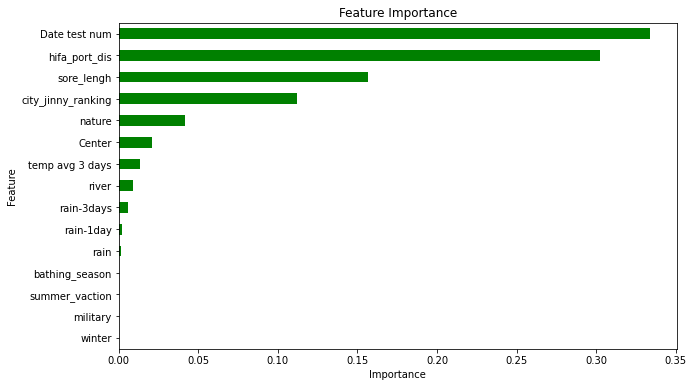

In [4]:
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))
global_importances = pd.Series(mlr.feature_importances_, index=X_train.columns)
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='green')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.show()